## A prototype model for identifying key mutations for FIPV/FECV switch

### 1. Minimum implementation of GWAS-like statistical test

In [3]:
# Arial fontがないためこちらで実行
import pandas as pd
import numpy as np
from Bio import SeqIO
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.font_manager import FontProperties, findfont

# 1. SVGのフォント設定（テキストとして保持する設定）
mpl.rcParams['svg.fonttype'] = 'none'

# 2. Arialフォントをシステムから検索して設定
try:
    # Arialを探し、パスを取得
    arial_path = findfont(FontProperties(family='Arial'))
    # FontPropertiesを生成
    arial_font = FontProperties(fname=arial_path)
    # matplotlibに適用
    plt.rcParams['font.family'] = arial_font.get_name()
    print(f"Arialフォントを適用しました: {arial_path}")
except Exception as e:
    print(f"Arialが見つかりません。デフォルトフォントを使用します: {e}")
    plt.rcParams['font.family'] = 'sans-serif'

Arialフォントを適用しました: /System/Library/Fonts/Supplemental/Arial.ttf


In [4]:
meta = pd.read_csv("FCoV1_full_ORF_meta_20260311.tsv", sep="\t")
meta

,Accession,biotype,Organism_Name,Isolate,Species,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI
...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,h7,FIPV,Feline coronavirus,h7,Alphacoronavirus suis,29065,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-07-04,NaN,Izumi
113,h2,FIPV,Feline coronavirus,h2,Alphacoronavirus suis,29273,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-03-24,NaN,Izumi
114,r3,FIPV,Feline coronavirus,r3,Alphacoronavirus suis,27502,Hokkaido,Japan,Felis catus,peritoneal effusion,2024-04-24,NaN,Izumi
115,v1,FIPV,Feline coronavirus,v1,Alphacoronavirus suis,29285,Saitama,Japan,Felis catus,peritoneal effusion,2023-09-07,NaN,Izumi


In [5]:
# load protien alignment
ids = []
seqs = []

for rec in SeqIO.parse("extract_3c_cds_trim.aa.fasta", "fasta"):
    ids.append(rec.id)
    seqs.append(str(rec.seq))

df_fasta = pd.DataFrame({"ID": ids, "Seq": seqs})
df_fasta

,ID,Seq
0,PQ416775.1,MIGGLFLNTLSFIVTNQHVIVNNTPHVNSLVQQHHVVSAN--IKSF...
1,PX315748.1,MIGGLFLNTLSFIVTNQHVAVNNTPHVGSTTLQHHVVNVN--IKSF...
2,PX315749.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...
3,PX315750.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...
4,PX315751.1,MIGGLFLNTLSFIVTNQHVVGNNTPHTQTVVQQHHVVSAN--IKNF...
...,...,...
111,h7,MIGGLFLNTLSFIVTNQHVVANNTPHFNAIVQQHHVVSAN--IKSS...
112,h2,MIGGLFLNTLSFIVTKQHVIVNNTSHVNSIVQQHHVVSAN--IKSF...
113,r3,MIGGLFLNTLSFIVTNQHVIVNNTPQVNFIVQQHHVVSAN--INSF...
114,v1,MIGGLFLNTLSFIVTNQHVVVNNTPHVNSIVQQHHVVSAN--IKSF...


In [6]:
df_fasta['X_count'] = df_fasta['Seq'].str.count('X')
df_fasta

,ID,Seq,X_count
0,PQ416775.1,MIGGLFLNTLSFIVTNQHVIVNNTPHVNSLVQQHHVVSAN--IKSF...,2
1,PX315748.1,MIGGLFLNTLSFIVTNQHVAVNNTPHVGSTTLQHHVVNVN--IKSF...,4
2,PX315749.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,3
3,PX315750.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,1
4,PX315751.1,MIGGLFLNTLSFIVTNQHVVGNNTPHTQTVVQQHHVVSAN--IKNF...,1
...,...,...,...
111,h7,MIGGLFLNTLSFIVTNQHVVANNTPHFNAIVQQHHVVSAN--IKSS...,1
112,h2,MIGGLFLNTLSFIVTKQHVIVNNTSHVNSIVQQHHVVSAN--IKSF...,3
113,r3,MIGGLFLNTLSFIVTNQHVIVNNTPQVNFIVQQHHVVSAN--INSF...,2
114,v1,MIGGLFLNTLSFIVTNQHVVVNNTPHVNSIVQQHHVVSAN--IKSF...,4


In [7]:
df_merged = pd.merge(meta, df_fasta, how="inner", left_on="Accession", right_on="ID")
df_merged

,Accession,biotype,Organism_Name,Isolate,Species,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,MIGGLFLNTLSFIVTNQHVIVNNTPHVNSLVQQHHVVSAN--IKSF...,2
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,MIGGLFLNTLSFIVTNQHVAVNNTPHVGSTTLQHHVVNVN--IKSF...,4
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,3
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,1
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,MIGGLFLNTLSFIVTNQHVVGNNTPHTQTVVQQHHVVSAN--IKNF...,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,h7,FIPV,Feline coronavirus,h7,Alphacoronavirus suis,29065,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-07-04,NaN,Izumi,h7,MIGGLFLNTLSFIVTNQHVVANNTPHFNAIVQQHHVVSAN--IKSS...,1
112,h2,FIPV,Feline coronavirus,h2,Alphacoronavirus suis,29273,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-03-24,NaN,Izumi,h2,MIGGLFLNTLSFIVTKQHVIVNNTSHVNSIVQQHHVVSAN--IKSF...,3
113,r3,FIPV,Feline coronavirus,r3,Alphacoronavirus suis,27502,Hokkaido,Japan,Felis catus,peritoneal effusion,2024-04-24,NaN,Izumi,r3,MIGGLFLNTLSFIVTNQHVIVNNTPQVNFIVQQHHVVSAN--INSF...,2
114,v1,FIPV,Feline coronavirus,v1,Alphacoronavirus suis,29285,Saitama,Japan,Felis catus,peritoneal effusion,2023-09-07,NaN,Izumi,v1,MIGGLFLNTLSFIVTNQHVVVNNTPHVNSIVQQHHVVSAN--IKSF...,4


In [8]:
df_merged_filtered = df_merged[df_merged['X_count'] < 100]
# replace 'FECV' in 'FECV_or_FIPV' with '0' and 'FIPV' with '1' and 'unknown' with '' for better encoding
df_merged_filtered['FECV_or_FIPV_encodes'] = df_merged_filtered['biotype'].replace({'FECV': '0', 'FIPV': '1', 'unknown': ''})
df_merged_filtered

,Accession,biotype,Organism_Name,Isolate,Species,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count,FECV_or_FIPV_encodes
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,MIGGLFLNTLSFIVTNQHVIVNNTPHVNSLVQQHHVVSAN--IKSF...,2,1
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,MIGGLFLNTLSFIVTNQHVAVNNTPHVGSTTLQHHVVNVN--IKSF...,4,1
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,3,1
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,1,1
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,MIGGLFLNTLSFIVTNQHVVGNNTPHTQTVVQQHHVVSAN--IKNF...,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,h7,FIPV,Feline coronavirus,h7,Alphacoronavirus suis,29065,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-07-04,NaN,Izumi,h7,MIGGLFLNTLSFIVTNQHVVANNTPHFNAIVQQHHVVSAN--IKSS...,1,1
112,h2,FIPV,Feline coronavirus,h2,Alphacoronavirus suis,29273,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-03-24,NaN,Izumi,h2,MIGGLFLNTLSFIVTKQHVIVNNTSHVNSIVQQHHVVSAN--IKSF...,3,1
113,r3,FIPV,Feline coronavirus,r3,Alphacoronavirus suis,27502,Hokkaido,Japan,Felis catus,peritoneal effusion,2024-04-24,NaN,Izumi,r3,MIGGLFLNTLSFIVTNQHVIVNNTPQVNFIVQQHHVVSAN--INSF...,2,1
114,v1,FIPV,Feline coronavirus,v1,Alphacoronavirus suis,29285,Saitama,Japan,Felis catus,peritoneal effusion,2023-09-07,NaN,Izumi,v1,MIGGLFLNTLSFIVTNQHVVVNNTPHVNSIVQQHHVVSAN--IKSF...,4,1


In [9]:
df_selected = df_merged_filtered[['Accession', 'Seq', 'FECV_or_FIPV_encodes']]
df_selected = df_selected[df_selected['FECV_or_FIPV_encodes'] != '']
df_selected.rename(columns={'FECV_or_FIPV_encodes': 'FIP_label'}, inplace=True)
df_selected.reset_index(drop=True, inplace=True)
df_selected

,Accession,Seq,FIP_label
0,PQ416775.1,MIGGLFLNTLSFIVTNQHVIVNNTPHVNSLVQQHHVVSAN--IKSF...,1
1,PX315748.1,MIGGLFLNTLSFIVTNQHVAVNNTPHVGSTTLQHHVVNVN--IKSF...,1
2,PX315749.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,1
3,PX315750.1,MIGGLFLNTLSFIVTTQHVVINNTPHVNSIVQQHHVVSAS--IKSF...,1
4,PX315751.1,MIGGLFLNTLSFIVTNQHVVGNNTPHTQTVVQQHHVVSAN--IKNF...,1
...,...,...,...
111,h7,MIGGLFLNTLSFIVTNQHVVANNTPHFNAIVQQHHVVSAN--IKSS...,1
112,h2,MIGGLFLNTLSFIVTKQHVIVNNTSHVNSIVQQHHVVSAN--IKSF...,1
113,r3,MIGGLFLNTLSFIVTNQHVIVNNTPQVNFIVQQHHVVSAN--INSF...,1
114,v1,MIGGLFLNTLSFIVTNQHVVVNNTPHVNSIVQQHHVVSAN--IKSF...,1


### FECVをconsensusにした上でアミノ酸の性質変化も考慮して再検討

In [17]:
# FECV consensusの作成
from collections import Counter

# 1. FECVのみ抽出
fecv_df = df_merged_filtered[df_merged_filtered['biotype'] == 'FECV'].copy()

# 2. seqをリスト形式に展開して各ポジションを列にする
# 注意: seqが文字列の場合、リストに変換してDataFrame化します
seq_matrix = pd.DataFrame([list(s) for s in fecv_df['Seq']])

# 3. コンセンサス配列の決定 (各列で最も頻度が高い文字)
consensus = seq_matrix.mode().iloc[0]

# 4. 多型サイトの特定 (ユニークなアミノ酸が2種類以上ある列)
polymorphic_sites = []
for col in seq_matrix.columns:
    counts = seq_matrix[col].value_counts()
    if len(counts) > 1:
        # ポジション（0-indexed）、アミノ酸の種類とカウントを記録
        polymorphic_sites.append({
            'position': col + 1, # 1-based indexにする場合
            'variation': dict(counts)
        })

poly_table = pd.DataFrame(polymorphic_sites)

In [18]:
# コンセンサス配列をリストに変換
consensus_list = consensus.tolist()
# 「一つの長い文字列」にしたい場合
consensus_str = "".join(consensus_list)
print(consensus_str)

MIGGLFLNTLSFIVTNQHVIVNNTPHVNSIVQQHHVVSAN--IKSFHLEFSIAVLFVLFLALYRSTNFKVCVGVLMFKIVSMTL--IGPMLIAFGYYIDGIVTTTVLALRFIYLAYFWYVNSRFEFILYNTTTLMFVHDRAAPFMRSSHGSIYVTLYGGINYMFVNDLTLHFVDPMLVGIAIRGLVRADLTVVRAVELLNGDFIYIFSQEAVVGVYNAAFSQAVINEIDLKEEEERVYDVSX


In [19]:
# 多型テーブルの表示
print("--- 多型サイト一覧 ---")
print(poly_table.head(10))

len(poly_table['position'])

--- 多型サイト一覧 ---
   position                   variation
0        11           {'S': 46, 'G': 3}
1        13           {'I': 48, 'M': 1}
2        15           {'T': 48, 'N': 1}
3        16   {'N': 42, 'T': 4, 'S': 3}
4        17           {'Q': 48, 'H': 1}
5        18           {'H': 48, 'Y': 1}
6        19           {'V': 48, 'A': 1}
7        20  {'I': 30, 'V': 17, 'T': 2}
8        21           {'V': 47, 'A': 2}
9        25           {'P': 47, 'S': 2}


63

In [20]:
# 多型の閾値設定 (例: 2種類以上、3種類以上など)
threshold = 4  # ここを 3 に変えれば「3種類以上の多型」を抽出します

polymorphic_sites = []
for col in seq_matrix.columns:
    counts = seq_matrix[col].value_counts()
    
    # 閾値でフィルタリング
    if len(counts) >= threshold:
        polymorphic_sites.append({
            'position': col + 1,
            'variation': dict(counts),
            'unique_types': len(counts) # 何種類あるか記録しておくと便利です
        })

poly_table = pd.DataFrame(polymorphic_sites)
print("--- 多型サイト一覧 ---")
print(poly_table.head(10))
len(poly_table['position'])

--- 多型サイト一覧 ---
   position                          variation  unique_types
0        27  {'V': 42, 'F': 4, 'A': 2, 'I': 1}             4
1        28  {'N': 38, 'D': 9, 'H': 1, 'S': 1}             4
2        29  {'S': 34, 'T': 8, 'P': 6, 'G': 1}             4
3        30  {'I': 41, 'V': 5, 'T': 2, 'L': 1}             4
4        31  {'V': 43, 'L': 3, 'I': 2, 'X': 1}             4
5        70  {'V': 41, 'A': 4, 'M': 2, 'T': 2}             4


6

In [21]:
# input
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(dtype=int)

# 多数決で決定したコンセンサス(多型は考慮せず)
fecv_consensus = "MIVLLLALLSTVRSEDAPHG-VTLPQFNTSHNNDKFELNFYNFLQTWDIPPNTETILGGYLPYCGEGDNCGWYNTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTPV----TVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTHVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTALGGEKLGGFYFDGLSSLLPPTIGKRSAVEDLLFNKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDDNKMAMYTASLIGGMAMGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNTMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLTQYAEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTEWEEVTAWSGICVNDTYAYVLKDFEYSIFSYNGTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPELDLQLEIFNQTKLNLTAEIDQLEQRADNLTNIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVVVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX"
L = len(seqs[0])

AA_CLASS = {
    # hydrophobic / aliphatic
    "A": "hydrophobic",
    "V": "hydrophobic",
    "L": "hydrophobic",
    "I": "hydrophobic",
    "M": "hydrophobic",

    # aromatic
    "F": "aromatic",
    "Y": "aromatic",
    "W": "aromatic",

    # polar uncharged
    "S": "polar",
    "T": "polar",
    "N": "polar",
    "Q": "polar",

    # positively charged
    "K": "positive",
    "R": "positive",
    "H": "positive",

    # negatively charged
    "D": "negative",
    "E": "negative",

    # special cases
    "G": "special",
    "P": "special",
    "C": "special",

    # deletion
    #"-": "deletion",
}

INVALID_AA = set(["-", "X", "*", "?", "N"])  


def aa_class(aa):
    if aa in INVALID_AA:
        return None
    return AA_CLASS.get(aa, "other")


def fisher_from_mask(mask, y):
    a = int(np.sum(mask & (y == 1)))
    b = int(np.sum(mask & (y == 0)))
    c = int(np.sum((~mask) & (y == 1)))
    d = int(np.sum((~mask) & (y == 0)))

    OR = (a * d + 1e-9) / (b * c + 1e-9)
    _, p = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    return a, b, c, d, OR, p


records = []

for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    ref = fecv_consensus[pos]

    valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])

    if ref in INVALID_AA:
        continue

    col_valid = col[valid_mask]
    y_valid = y[valid_mask]

    if len(col_valid) < 3:
        continue

    uniq = np.unique(col_valid)

    # --------------------------------------------------
    # 1) exact mutation test
    # --------------------------------------------------
    for aa in uniq:
        if aa == ref:
            continue

        aa_mask = (col_valid == aa)
        a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)

        records.append({
            "test_type": "exact_aa",
            "feature": f"{ref}{pos+1}{aa}",
            "mutation": f"{ref}{pos+1}{aa}",
            "pos": pos + 1,
            "ref": ref,
            "aa": aa,
            "ref_class": aa_class(ref),
            "aa_class": aa_class(aa),
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 2) any mutation vs no mutation
    # --------------------------------------------------
    any_mut_mask = (col_valid != ref)
    # 変異あり/なしの両方が存在しないと検定できないので確認
    if np.any(any_mut_mask) and np.any(~any_mut_mask):
        a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)

        records.append({
            "test_type": "any_mutation",
            "feature": f"{ref}{pos+1}mut",
            "mutation": f"{ref}{pos+1}mut",
            "pos": pos + 1,
            "ref": ref,
            "aa": None,
            "ref_class": aa_class(ref),
            "aa_class": None,
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 3) class changed vs not changed
    # --------------------------------------------------
    ref_cls = aa_class(ref)
    col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)

    cls_valid_mask = np.array([c is not None for c in col_cls])
    col_valid2 = col_valid[cls_valid_mask]
    col_cls2 = col_cls[cls_valid_mask]
    y_valid2 = y_valid[cls_valid_mask]

    if len(col_valid2) >= 3 and ref_cls is not None:
        class_changed_mask = (col_cls2 != ref_cls)

        if np.any(class_changed_mask) and np.any(~class_changed_mask):
            a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)

            records.append({
                "test_type": "class_changed",
                "feature": f"{ref}{pos+1}class_change",
                "mutation": f"{ref}{pos+1}class_change",
                "pos": pos + 1,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": "different_from_ref_class",
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

    # --------------------------------------------------
    # 4) target class specific tests
    # --------------------------------------------------
    observed_classes = sorted(set([c for c in col_cls if c is not None]))
    for target_cls in observed_classes:
        if target_cls == ref_cls:
            continue

        target_class_mask = (col_cls2 == target_cls)

        if np.any(target_class_mask) and np.any(~target_class_mask):
            a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)

            records.append({
                "test_type": "target_class",
                "feature": f"{ref}{pos+1}{target_cls}",
                "mutation": f"{ref}{pos+1}{target_cls}",
                "pos": pos + 1,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": target_cls,
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

# =========================
# result table
# =========================
res = pd.DataFrame(records)

res["p_corrected_global"] = multipletests(res["p"], method="fdr_bh")[1]

res["p_corrected_by_type"] = np.nan
for t, idx in res.groupby("test_type").groups.items():
    res.loc[idx, "p_corrected_by_type"] = multipletests(res.loc[idx, "p"], method="fdr_bh")[1]

# =========================
# site summary
# =========================
site_summary = (
    res.groupby(["pos", "test_type"])
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

site_summary_overall = (
    res.groupby("pos")
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

In [22]:
site_summary

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,187,exact_aa,0.694967,0.420360,2.461509e+01,3
1,87,any_mutation,1.000000,0.094188,2.681231e+01,1
2,87,exact_aa,1.000000,1.000000,2.669453e+01,2
3,48,exact_aa,1.000000,1.000000,2.656100e+01,2
4,214,exact_aa,1.000000,1.000000,2.622452e+01,3
...,...,...,...,...,...,...
365,227,exact_aa,1.000000,1.000000,1.000000e-09,1
366,231,exact_aa,1.000000,1.000000,1.000000e-09,1
367,234,exact_aa,1.000000,1.000000,1.000000e-09,1
368,242,exact_aa,1.000000,1.000000,1.000000e-09,3


In [23]:
site_summary_overall

,pos,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,187,0.694967,0.420360,2.461509e+01,5
1,87,1.000000,0.094188,2.681231e+01,5
2,48,1.000000,1.000000,2.656100e+01,2
3,214,1.000000,1.000000,2.622452e+01,6
4,232,1.000000,1.000000,2.622452e+01,5
...,...,...,...,...,...
195,225,1.000000,1.000000,1.000000e-09,1
196,227,1.000000,1.000000,1.000000e-09,1
197,231,1.000000,1.000000,1.000000e-09,1
198,234,1.000000,1.000000,1.000000e-09,1


### stop codonの有無による検定

In [ ]:
# 終始コドンが入っているもののリストをマニュアルで目で見てカウント
list_stop = 'PX315755.1,PX315756.1,OP542206.1,HQ012367.1,HQ012369.1,HQ012370.1,HQ392472.1,FJ938058.1,FJ938055.1,DQ848678.1,c77,c46,c63,v11,v7,r2,v1,v5,h6'

# カンマで分割してリスト化
stop_ids = list_stop.split(',')

# リストの要素数を表示
print(f"要素数: {len(stop_ids)}")

要素数: 19


In [ ]:
# stop codonのある配列の確認
from Bio import SeqIO
import pandas as pd

def find_internal_stop_codons_in_file(fasta_file):
    # 終止コドンのセット
    stop_codons = {'TAA', 'TAG', 'TGA'}
    anomalous_records = []

    for record in SeqIO.parse(fasta_file, "fasta"):
        seq = str(record.seq).upper()
        
        # 3塩基ずつに区切る
        # 配列長が3の倍数であることを前提としていますが、そうでない場合も考慮しつつループ
        codons = [seq[i:i+3] for i in range(0, len(seq) - (len(seq) % 3), 3)]
        
        # 配列の全コドンから、最後の1つ（本来の終止コドン）を除いた部分をスキャン
        internal_codons = codons[:-1]
        
        for i, codon in enumerate(internal_codons):
            if codon in stop_codons:
                anomalous_records.append({
                    "Accession": record.id,
                    "Internal_Stop_Pos": i + 1,  # 何番目のコドンか
                    "Stop_Codon": codon
                })
                # 同じ配列内に複数あっても、とりあえず「内部Stopあり」としてリスト化するためbreak
                break 
                
    return pd.DataFrame(anomalous_records)

# 実行
df_stops = find_internal_stop_codons_in_file("extract_3c_cds.fasta")

print(f"--- 内部ストップコドンを含む配列数: {len(df_stops)} ---")
display(df_stops)

--- 内部ストップコドンを含む配列数: 19 ---


,Accession,Internal_Stop_Pos,Stop_Codon
0,PX315755.1,17,TAA
1,PX315756.1,17,TAA
2,OP542206.1,216,TAG
3,HQ392472.1,140,TGA
4,HQ012367.1,17,TAA
5,HQ012369.1,4,TGA
6,HQ012370.1,4,TGA
7,FJ938055.1,110,TGA
8,FJ938058.1,222,TAG
9,DQ848678.1,17,TAA


In [21]:
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

# 1. リストの準備
list_stop_str = 'PX315755.1,PX315756.1,OP542206.1,HQ012367.1,HQ012369.1,HQ012370.1,HQ392472.1,FJ938058.1,FJ938055.1,DQ848678.1,c77,c46,c63,v11,v7,r2,v1,v5,h6'
stop_ids = [id.strip() for id in list_stop_str.split(',')]

# 2. Stop codon 有無のフラグを作成
# df_selected の 'Accession' カラムに含まれているかを判定
df_selected['has_stop'] = df_selected['Accession'].isin(stop_ids)
y = df_selected["FIP_label"].to_numpy(int)
has_stop = df_selected['has_stop'].to_numpy()

# 3. 2×2分割表の作成
# a: Stopあり ∩ FIPV, b: Stopあり ∩ FECV
# c: Stopなし ∩ FIPV, d: Stopなし ∩ FECV
a = int(np.sum(has_stop & (y == 1)))
b = int(np.sum(has_stop & (y == 0)))
c = int(np.sum((~has_stop) & (y == 1)))
d = int(np.sum((~has_stop) & (y == 0)))

# 4. フィッシャーの正確確率検定
OR = (a * d + 1e-9) / ((b * c) + 1e-9)
p_value, _ = fisher_exact([[a, b], [c, d]], alternative="two-sided")

# 5. 結果の表示
stop_res = pd.DataFrame([{
    "Feature": "Internal Stop Codon",
    "FIPV_with_stop": a,
    "FECV_with_stop": b,
    "FIPV_without_stop": c,
    "FECV_without_stop": d,
    "Odds_Ratio": OR,
    "p_value": p_value
}])
stop_res

,Feature,FIPV_with_stop,FECV_with_stop,FIPV_without_stop,FECV_without_stop,Odds_Ratio,p_value
0,Internal Stop Codon,19,0,48,49,931000000000.999878,inf


# stop codon の出現posの可視化

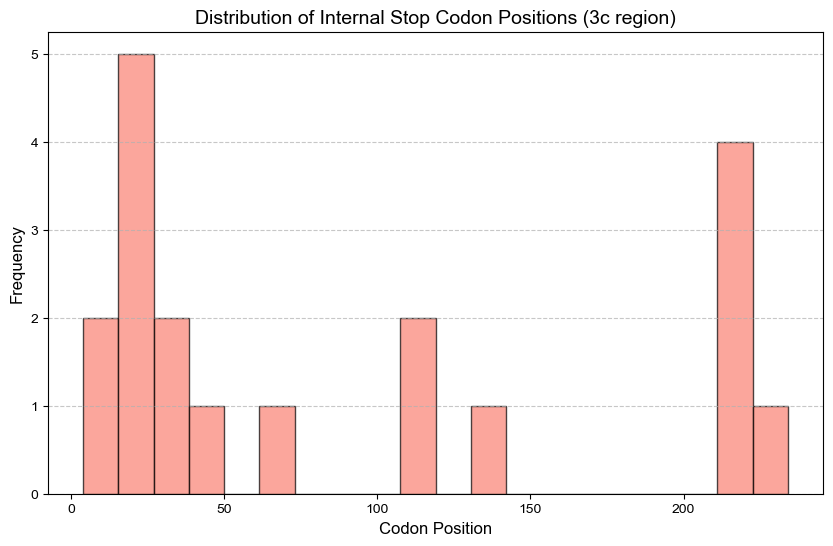

In [18]:

import matplotlib.pyplot as plt

# 1. 19個のリストに含まれる配列のStopコドン位置を特定
# 先ほどの find_internal_stop_codons_in_file の結果 (df_stops) を利用
# もし df_stops がない場合は、再度抽出します
internal_stop_positions = df_stops[df_stops['Accession'].isin(stop_ids)]['Internal_Stop_Pos']

# 2. ヒストグラムの作成
plt.figure(figsize=(10, 6))
plt.hist(internal_stop_positions, bins=20, color='salmon', edgecolor='black', alpha=0.7)

plt.title('Distribution of Internal Stop Codon Positions (3c region)', fontsize=14)
plt.xlabel('Codon Position', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 3. 保存または表示
plt.show()